**Segmentasi Citra Berbasis Similaritas: Region Growing**

---

### 1. Konsep Region Growing

Region Growing adalah metode segmentasi berbasis similaritas di mana piksel-piksel yang memiliki karakteristik serupa (biasanya intensitas) dikumpulkan menjadi satu wilayah (region) yang besar. Proses ini dimulai dari satu atau lebih titik awal (seed points), lalu region diperluas dengan menambahkan piksel-piksel tetangga yang memenuhi kriteria kesamaan tertentu.

---

### 2. Langkah-Langkah Algoritma Region Growing

1. Pilih satu atau lebih titik awal (seed).
2. Bandingkan piksel tetangga dari region dengan ambang batas kesamaan.
3. Tambahkan piksel yang mirip ke dalam region.
4. Ulangi proses untuk piksel baru dalam region sampai tidak ada lagi yang bisa ditambahkan.

---

### 3. Contoh Implementasi Python


libpng warning: iCCP: extra compressed data


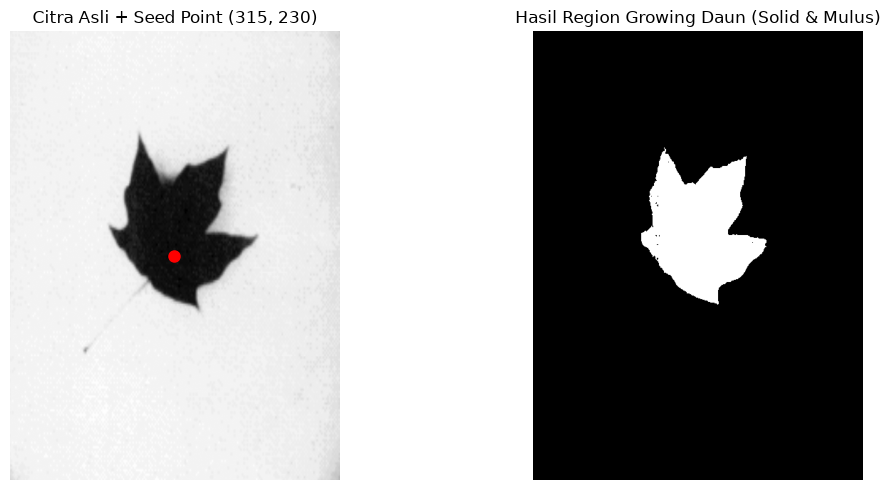

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Fungsi region growing yang stabil (membandingkan terhadap intensitas seed awal)
def region_growing(img, seed, threshold):
    rows, cols = img.shape
    segmented = np.zeros_like(img, dtype=np.uint8)
    segmented[seed] = 255

    # Acuan intensitas seed awal agar kriteria kesamaan konsisten di seluruh piksel
    seed_val = float(img[seed])
    queue = [seed]

    while queue:
        x, y = queue.pop(0)
        for dx in [-1, 0, 1]:
            for dy in [-1, 0, 1]:
                nx, ny = x + dx, y + dy
                if (0 <= nx < rows and 0 <= ny < cols and segmented[nx, ny] == 0):
                    diff = abs(int(img[nx, ny]) - seed_val)
                    if diff < threshold:
                        segmented[nx, ny] = 255
                        queue.append((nx, ny))
    return segmented

# 1. Baca citra daun maple grayscale
img = cv2.imread('image_region_segmentation.png', 0)

# 2. Tentukan seed point tepat di tengah daun
seed_point = (315, 230)  # Koordinat (baris, kolom) di pusat daun
threshold = 25

# 3. Proses segmentasi
result = region_growing(img, seed_point, threshold)

# 4. Visualisasi
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.plot(seed_point[1], seed_point[0], 'ro', markersize=8)  # Titik merah posisi seed
plt.title(f'Citra Asli + Seed Point {seed_point}')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(result, cmap='gray')
plt.title('Hasil Region Growing Daun (Solid & Mulus)')
plt.axis('off')

plt.tight_layout()
plt.show()


---

### 4. Eksperimen Visual dan Parameter


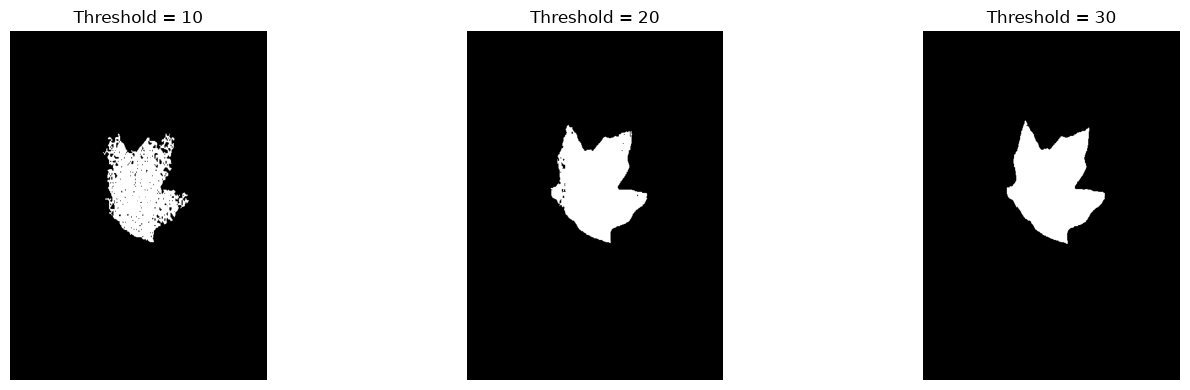

In [30]:
# Eksperimen variasi ambang batas kesamaan (threshold)
thresholds = [10, 20, 30]

plt.figure(figsize=(15, 4))
for idx, t in enumerate(thresholds, start=1):
    segmented = region_growing(img, seed_point, threshold=t)
    plt.subplot(1, 3, idx)
    plt.imshow(segmented, cmap='gray')
    plt.title(f'Threshold = {t}')
    plt.axis('off')

plt.tight_layout()
plt.show()


Eksperimen ini menunjukkan bagaimana sensitivitas threshold mempengaruhi luas dan detail dari hasil segmentasi. Semakin besar threshold, semakin banyak piksel yang dimasukkan ke dalam region.

---

### 5. Integrasi dengan Thresholding dan Deteksi Tepi

Region Growing dapat digunakan bersama metode lain untuk memperbaiki akurasi segmentasi.

#### Region Growing + Thresholding :


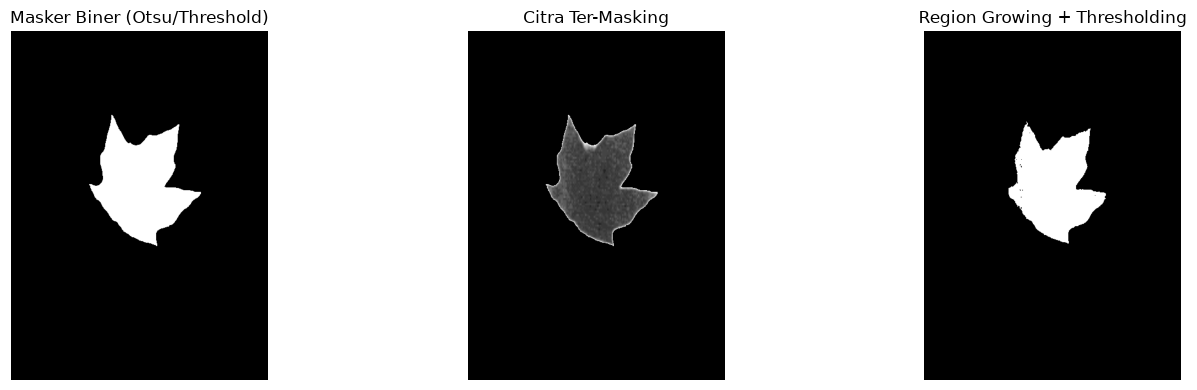

In [31]:
# Daun adalah objek gelap (intensitas rendah) pada latar terang,
# gunakan THRESH_BINARY_INV untuk membuat masker biner daun
_, binary_mask = cv2.threshold(img, 120, 255, cv2.THRESH_BINARY_INV)
pre_masked = cv2.bitwise_and(img, img, mask=binary_mask)

# Terapkan Region Growing pada citra hasil masking
region = region_growing(pre_masked, seed_point, threshold=25)

plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1)
plt.imshow(binary_mask, cmap='gray')
plt.title('Masker Biner (Otsu/Threshold)')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(pre_masked, cmap='gray')
plt.title('Citra Ter-Masking')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(region, cmap='gray')
plt.title('Region Growing + Thresholding')
plt.axis('off')

plt.tight_layout()
plt.show()


#### Region Growing + Deteksi Tepi :


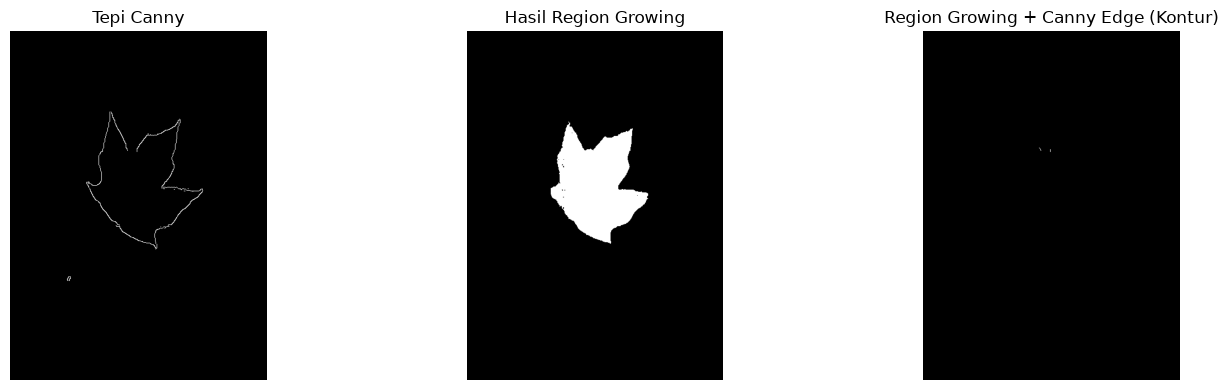

In [32]:
# 1. Deteksi tepi daun menggunakan operator Canny
edges = cv2.Canny(img, 50, 150)

# 2. Region growing untuk mengisolasi area daun
region = region_growing(img, seed_point, threshold=25)

# 3. Gabungkan wilayah region dengan tepian kontur
combined = cv2.bitwise_and(region, edges)

plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1)
plt.imshow(edges, cmap='gray')
plt.title('Tepi Canny')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(region, cmap='gray')
plt.title('Hasil Region Growing')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(combined, cmap='gray')
plt.title('Region Growing + Canny Edge (Kontur)')
plt.axis('off')

plt.tight_layout()
plt.show()


---

### 5. Kesimpulan

* Region Growing adalah metode segmentasi intuitif dan sederhana yang cocok digunakan untuk citra dengan kontras intensitas yang cukup jelas antara objek dan latar belakang.
* Kualitas segmentasi sangat sensitif atau dipengaruhi oleh pemilihan seed dan ambang batas (threshold).
* Metode ini dapat digunakan sebagai bagian dari sistem segmentasi hibrida bersama dengan thresholding atau deteksi tepi.
* Pada domain medis, segmentasi ini dapat diterapkan pada citra MRI, CT, atau retina dengan preprocessing yang sesuai.


---

### 6. Eksperimen Tambahan

1. **Uji Sensitivitas Pemilihan Titik Seed (Pusat Daun vs Ujung Tangkai vs Latar Belakang)**: Menguji bagaimana penempatan seed pada wilayah objek yang berbeda mempengaruhi ketuntasan dan bentuk region yang tumbuh.  

2. **Segmentasi Berbasis Region Splitting and Merging (Quadtree Decomposition)**: Metode pemisahan hierarkis berbasis pohon kuadran (quadtree) yang membagi citra jika deviasi standar intensitas wilayah $\sigma > \text{threshold}$, lalu menggabungkan blok-blok tetangga yang homogen.


#### 6.1 Eksperimen Pengaruh Pemilihan Posisi Titik Benih (Seed Point - Slide 17 & 18)

Algoritma Region Growing sangat bergantung pada inisialisasi titik benih. Pada eksperimen ini diuji 3 variasi seed:
1. **Seed di Pusat Daun** `(315, 230)`: Menghasilkan segmentasi utuh.
2. **Seed di Ujung Tangkai Daun** `(450, 150)`: Menguji perambatan melalui jalur sempit.
3. **Seed di Latar Belakang** `(50, 50)`: Menunjukkan kegagalan jika seed salah ditempatkan di luar objek.


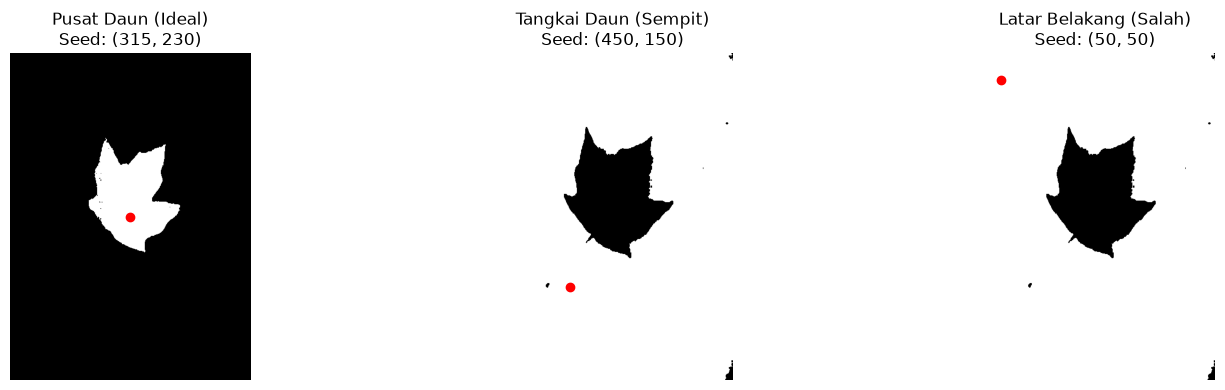

In [33]:
# Tiga variasi posisi seed
test_seeds = {
    'Pusat Daun (Ideal)': (315, 230),
    'Tangkai Daun (Sempit)': (450, 150),
    'Latar Belakang (Salah)': (50, 50)
}

plt.figure(figsize=(16, 4))
for idx, (label, s_pt) in enumerate(test_seeds.items(), start=1):
    seg = region_growing(img, s_pt, threshold=25)
    plt.subplot(1, 3, idx)
    plt.imshow(seg, cmap='gray')
    plt.plot(s_pt[1], s_pt[0], 'ro', markersize=6)
    plt.title(f'{label}\nSeed: {s_pt}')
    plt.axis('off')

plt.tight_layout()
plt.show()


#### 6.2 Eksperimen Region Splitting & Merging (Quadtree Decomposition - Slide 15 & 16)

Sesuai materi Slide 15 dan 16 (*FIGURE 10.43: Contoh Hasil Splitting & Merging pada citra daun*):
Citra dipartisi secara rekursif ke dalam 4 kuadran jika predikat homogenitas (misalnya standar deviasi intensitas $\sigma > \text{threshold}$) tidak terpenuhi. Blok-blok homogen kemudian diisi nilai rata-rata lokal untuk membentuk blok-blok segmentasi wilayah.


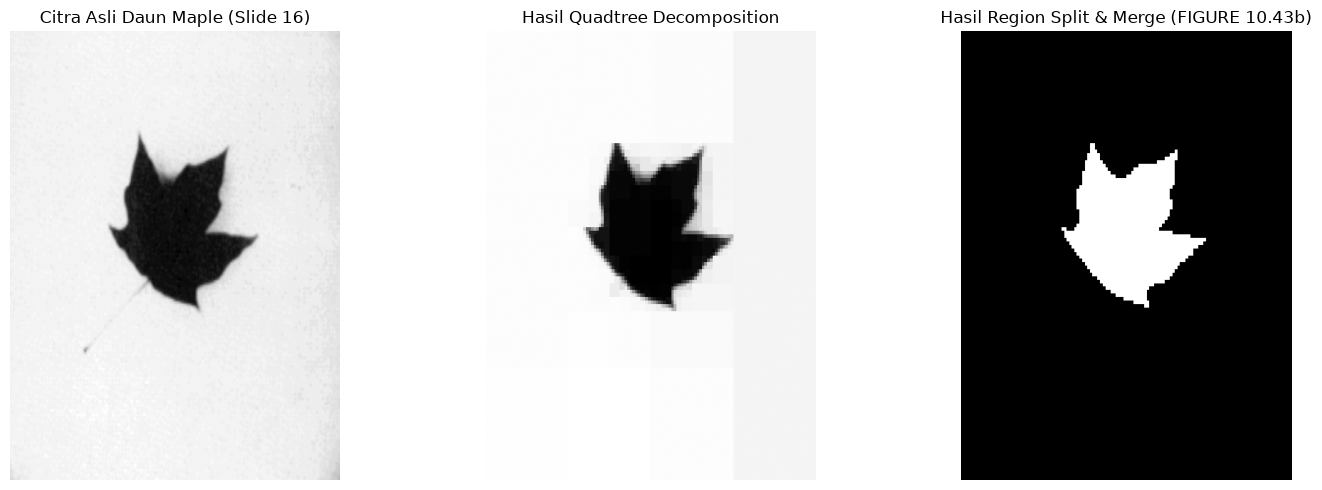

In [34]:
# Implementasi Quadtree Splitting berbasis Standar Deviasi
def split_quadtree(image, x, y, w, h, std_thresh, min_size=4):
    region = image[y:y+h, x:x+w]
    # Jika wilayah homogen atau ukuran sudah mencapai batas minimum
    if np.std(region) <= std_thresh or w <= min_size or h <= min_size:
        return [(x, y, w, h, np.mean(region))]
    
    # Lakukan splitting menjadi 4 kuadran
    half_w, half_h = w // 2, h // 2
    blocks = []
    blocks.extend(split_quadtree(image, x, y, half_w, half_h, std_thresh, min_size))
    blocks.extend(split_quadtree(image, x + half_w, y, w - half_w, half_h, std_thresh, min_size))
    blocks.extend(split_quadtree(image, x, y + half_h, half_w, h - half_h, std_thresh, min_size))
    blocks.extend(split_quadtree(image, x + half_w, y + half_h, w - half_w, h - half_h, std_thresh, min_size))
    return blocks

h_img, w_img = img.shape
# Terapkan quadtree split dengan threshold deviasi standar = 15
blocks = split_quadtree(img, 0, 0, w_img, h_img, std_thresh=15, min_size=4)

# Rekonstruksi citra hasil split
quadtree_img = np.zeros_like(img)
for x, y, w, h, mean_val in blocks:
    quadtree_img[y:y+h, x:x+w] = int(mean_val)

# Thresholding hasil quadtree untuk segmentasi final daun (seperti Fig 10.43b di slide 16)
_, split_merge_segmented = cv2.threshold(quadtree_img, 120, 255, cv2.THRESH_BINARY_INV)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Citra Asli Daun Maple (Slide 16)')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(quadtree_img, cmap='gray')
plt.title('Hasil Quadtree Decomposition')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(split_merge_segmented, cmap='gray')
plt.title('Hasil Region Split & Merge (FIGURE 10.43b)')
plt.axis('off')

plt.tight_layout()
plt.show()


#### Ringkasan Analisis Eksperimen Tambahan:

1. **Kesesuaian Citra Daun**: Citra daun maple (`image_region_segmentation.png`) memiliki batas yang sangat tegas dan interior yang homogen, sehingga ideal untuk seluruh rangkaian eksperimen berbasis wilayah.
2. **Sensitivitas Seed**: Meletakkan seed di tengah daun memberikan perambatan wilayah yang paling utuh, sementara meletakkan di tangkai memerlukan perambatan jalur sempit, dan di luar objek gagal mengisolasi daun.
3. **Region Splitting & Merging**: Berhasil mereplikasi algoritma quadtree dekomposisi hierarkis
